# IM-free wireless mic planner

**[Team name]**: [Member 1], [Member 2], [Member 3], [Member 4]
Qiskit Fall Fest 2026, University of Waterloo

Wireless mics fail in a way that surprises newcomers. When several mics transmit at once, their signals mix and create ghost signals at new frequencies. If a ghost lands on another mic's frequency, that mic crackles. Professionals plan around this with vendor software or a dedicated RF coordinator. This notebook turns the planning rules into a cost function on qubits and searches it with QAOA, behind one plain-English function:

```python
plan_mics(band="470-474 MHz", mics=5, step="250 kHz", spacing="500 kHz", im_guard="250 kHz")
```

The person using it never sees a QUBO, a Hamiltonian, a penalty weight or a mixer.

**What this is not.** QAOA is a heuristic. The demo has 4,368 possible plans, and brute force solves it in about 10 ms. We claim no speed-up. Our point is modelling: the intermodulation rules are three- and four-way interactions, QAOA takes them as they are, and the circuit itself keeps the mic count fixed.

**How to run.** Open this one file in Python 3.10 or newer and use Run all. The notebook carries its own code, and the Setup section installs any missing packages. Everything runs live on Qiskit's statevector simulator, in about two minutes on our laptop. Nothing is precomputed or loaded from a file.

## Setup

This notebook is one self-contained file. The cells in this section run first.

1. The next cell checks for the Python packages and installs any that are missing.
2. The collapsed cells after it write the `micplanner` package, about 1,100 lines of plain Python, into a folder called `micplanner_embedded` next to this notebook.

To read the code, click the `...` bar of a collapsed cell. If your viewer shows those cells expanded, scroll down to section 1.

In [1]:
import importlib, os, sys, time
from importlib.metadata import PackageNotFoundError, version

T0 = time.perf_counter()
TESTED_QISKIT = "2.6.1"
MINIMUM_QISKIT = (2, 1)


def packages_missing():
    try:
        for package in ("numpy", "scipy", "matplotlib"):
            version(package)
        return tuple(int(part) for part in version("qiskit").split(".")[:2]) < MINIMUM_QISKIT
    except PackageNotFoundError:
        return True


if packages_missing():
    %pip install -q "qiskit==2.6.1" numpy scipy matplotlib
    importlib.invalidate_caches()

print("Qiskit", version("qiskit"), "| SciPy", version("scipy"), "| Matplotlib", version("matplotlib"))
if version("qiskit") != TESTED_QISKIT:
    print(f"The numbers in the text come from Qiskit {TESTED_QISKIT}, so gate counts may differ slightly here.")

os.makedirs("micplanner_embedded/micplanner", exist_ok=True)
sys.path.append(os.path.abspath("micplanner_embedded"))

Qiskit 2.6.1 | SciPy 1.18.1 | Matplotlib 3.11.2


In [2]:
%%writefile micplanner_embedded/micplanner/__init__.py
"""IM-free wireless mic planner: plain-English frequency planning through QAOA."""

from .engine import build_instance, check_plan, brute_force

__all__ = ["build_instance", "check_plan", "brute_force", "plan_mics"]


def __getattr__(name):
    # plan_mics pulls in Qiskit, so import it only when asked for.
    if name == "plan_mics":
        from .api import plan_mics
        return plan_mics
    raise AttributeError(name)


Writing micplanner_embedded/micplanner/__init__.py


In [3]:
%%writefile micplanner_embedded/micplanner/engine.py
"""Band parsing, the frequency grid, IM enumeration, the violation checker and brute force.

All frequencies are stored as whole numbers of hertz so that "lands within 250 kHz"
never depends on floating-point rounding. Grid point k is qubit k and bit k of a plan mask.
"""

from __future__ import annotations

import re
import time
from bisect import bisect_left, bisect_right
from dataclasses import dataclass, field
from itertools import combinations
from math import comb

import numpy as np

_UNITS = {"hz": 1, "khz": 1_000, "mhz": 1_000_000, "ghz": 1_000_000_000}
_NUM = r"[-+]?\d+(?:\.\d*)?|[-+]?\.\d+"
_UNIT = r"[kKmMgG]?[hH][zZ]"


def parse_freq(text, default_unit="kHz") -> int:
    """Turn "250 kHz" or "472.5 MHz" into hertz. A bare number uses `default_unit`."""
    if isinstance(text, (int, float)):
        return round(text * _UNITS[default_unit.lower()])
    m = re.fullmatch(rf"\s*({_NUM})\s*({_UNIT})?\s*", text)
    if not m:
        raise ValueError(f"Can't read a frequency from {text!r}. Try something like '250 kHz'.")
    unit = (m.group(2) or default_unit).lower()
    return round(float(m.group(1)) * _UNITS[unit])


def parse_range(text, default_unit="MHz") -> tuple[int, int]:
    """Turn "470-474 MHz" (or "470 MHz to 474 MHz") into a (low, high) pair in hertz."""
    if isinstance(text, (tuple, list)) and len(text) == 2:
        lo, hi = (parse_freq(t, default_unit) for t in text)
    else:
        m = re.fullmatch(rf"\s*({_NUM})\s*({_UNIT})?\s*(?:-|–|to)\s*({_NUM})\s*({_UNIT})?\s*", text)
        if not m:
            raise ValueError(f"Can't read a range from {text!r}. Try something like '470-474 MHz'.")
        unit = (m.group(4) or m.group(2) or default_unit).lower()
        lo_unit = (m.group(2) or unit).lower()
        lo = round(float(m.group(1)) * _UNITS[lo_unit])
        hi = round(float(m.group(3)) * _UNITS[unit])
    if hi <= lo:
        raise ValueError(f"The range {text!r} is empty: the top must be above the bottom.")
    return lo, hi


def mhz(f_hz) -> float:
    return f_hz / 1_000_000


def fmt_mhz(f_hz) -> str:
    return f"{f_hz / 1_000_000:.3f} MHz"


def fmt_khz(f_hz) -> str:
    return f"{f_hz / 1_000:g} kHz"


@dataclass
class Instance:
    """A planning problem: the allowed grid points, the mic count and the rules.

    `pairs`, `triples` and `quads` hold one entry per conflicting set of grid points
    (sorted index tuples). They are the P, T and Q sets of the cost function.
    """

    freqs: list[int]
    n_mics: int
    spacing: int
    im_guard: int
    band: tuple[int, int] | None = None
    step: int | None = None
    exclusions: list[tuple[int, int]] = field(default_factory=list)
    pairs: list[tuple[int, int]] = field(default_factory=list)
    triples: list[tuple[int, int, int]] = field(default_factory=list)
    quads: list[tuple[int, int, int, int]] = field(default_factory=list)

    @property
    def n_points(self) -> int:
        return len(self.freqs)

    def terms(self):
        """All conflicting sets, P then T then Q."""
        return list(self.pairs) + list(self.triples) + list(self.quads)

    def describe(self) -> str:
        lines = [f"{self.n_points} allowed frequencies, {self.n_mics} mics"]
        if self.band:
            lines.append(f"band {fmt_mhz(self.band[0])} to {fmt_mhz(self.band[1])} (top edge excluded), "
                         f"step {fmt_khz(self.step)}")
        for lo, hi in self.exclusions:
            lines.append(f"excluded {fmt_mhz(lo)} to {fmt_mhz(hi)}")
        lines.append(f"carrier spacing at least {fmt_khz(self.spacing)}, "
                     f"IM products must stay at least {fmt_khz(self.im_guard)} from every carrier")
        lines.append(f"conflicting sets: {len(self.pairs)} pairs, {len(self.triples)} triples, "
                     f"{len(self.quads)} quadruples")
        return "\n".join(lines)


def make_grid(band, step, exclude=()) -> tuple[list[int], tuple[int, int], int, list[tuple[int, int]]]:
    """Grid points from the bottom of the band up to (not including) the top edge.

    A point inside any exclusion range (edges included) is dropped.
    """
    lo, hi = parse_range(band)
    step_hz = parse_freq(step)
    if step_hz <= 0:
        raise ValueError("The step must be positive.")
    excl = [parse_range(e) for e in exclude]
    freqs = []
    f = lo
    while f < hi:
        if not any(a <= f <= b for a, b in excl):
            freqs.append(f)
        f += step_hz
    return freqs, (lo, hi), step_hz, excl


def _near(freqs, value, guard):
    """Indices of carriers strictly less than `guard` away from `value` (freqs sorted)."""
    return range(bisect_right(freqs, value - guard), bisect_left(freqs, value + guard))


def enumerate_conflicts(freqs, spacing, im_guard):
    """Return the P, T and Q sets for a sorted list of grid frequencies (hertz)."""
    N = len(freqs)
    pairs = [(i, j) for i, j in combinations(range(N), 2) if abs(freqs[j] - freqs[i]) < spacing]
    triples = set()
    for k in range(N):
        for l in range(N):
            if l == k:
                continue
            for m in _near(freqs, 2 * freqs[k] - freqs[l], im_guard):
                if m != k and m != l:
                    triples.add(tuple(sorted((k, l, m))))
    quads = set()
    for k, l in combinations(range(N), 2):
        for p in range(N):
            if p == k or p == l:
                continue
            for m in _near(freqs, freqs[k] + freqs[l] - freqs[p], im_guard):
                if m not in (k, l, p):
                    quads.add(tuple(sorted((k, l, p, m))))
    return pairs, sorted(triples), sorted(quads)


def build_instance(band="470-474 MHz", mics=5, step="250 kHz", spacing="500 kHz",
                   im_guard="250 kHz", exclude=()) -> Instance:
    freqs, band_hz, step_hz, excl = make_grid(band, step, exclude)
    if mics < 1:
        raise ValueError("Ask for at least one mic.")
    if mics > len(freqs):
        raise ValueError(f"Only {len(freqs)} frequencies are allowed, so {mics} mics can't fit.")
    inst = Instance(freqs=freqs, n_mics=mics, spacing=parse_freq(spacing), im_guard=parse_freq(im_guard),
                    band=band_hz, step=step_hz, exclusions=excl)
    inst.pairs, inst.triples, inst.quads = enumerate_conflicts(freqs, inst.spacing, inst.im_guard)
    return inst


# ---------------------------------------------------------------------------
# Checking a plan

@dataclass
class Violation:
    kind: str            # "spacing", "two-tone" or "three-tone"
    sources: tuple       # the carriers that create it (hertz)
    product: int | None  # where the product lands (hertz); None for spacing
    victim: int          # the carrier that gets hit (hertz)

    def __str__(self):
        if self.kind == "spacing":
            a, b = self.sources
            return f"spacing: {fmt_mhz(a)} and {fmt_mhz(b)} are only {fmt_khz(abs(b - a))} apart"
        if self.kind == "two-tone":
            a, b = self.sources
            rule = f"2 x {fmt_mhz(a)} - {fmt_mhz(b)}"
        else:
            a, b, c = self.sources
            rule = f"{fmt_mhz(a)} + {fmt_mhz(b)} - {fmt_mhz(c)}"
        off = self.product - self.victim
        where = "right on" if off == 0 else f"{fmt_khz(abs(off))} from"
        return f"{self.kind}: {rule} = {fmt_mhz(self.product)}, {where} the mic at {fmt_mhz(self.victim)}"


@dataclass
class CheckResult:
    plan: list[int]
    violations: list[Violation]

    @property
    def counts(self) -> dict:
        out = {"spacing": 0, "two-tone": 0, "three-tone": 0}
        for v in self.violations:
            out[v.kind] += 1
        return out

    @property
    def clean(self) -> bool:
        return not self.violations

    def report(self) -> str:
        if self.clean:
            return "No spacing problems and no third-order product within the guard of any mic."
        c = self.counts
        head = (f"{len(self.violations)} problems: {c['spacing']} spacing, "
                f"{c['two-tone']} two-tone hits, {c['three-tone']} three-tone hits")
        return "\n".join([head] + ["  " + str(v) for v in self.violations])


def check_plan(plan_hz, spacing, im_guard) -> CheckResult:
    """List every problem in a plan of carrier frequencies (hertz).

    Every product is listed separately, so one evenly spaced triple shows up as two two-tone hits.
    Works for any frequencies, not just grid points.
    """
    f = sorted(int(x) for x in plan_hz)
    out = []
    for a, b in combinations(f, 2):
        if b - a < spacing:
            out.append(Violation("spacing", (a, b), None, b))
    for a in f:
        for b in f:
            if a == b:
                continue
            prod = 2 * a - b
            for c in _near(f, prod, im_guard):
                if f[c] not in (a, b):
                    out.append(Violation("two-tone", (a, b), prod, f[c]))
    for a, b in combinations(f, 2):
        for c in f:
            if c in (a, b):
                continue
            prod = a + b - c
            for d in _near(f, prod, im_guard):
                if f[d] not in (a, b, c):
                    out.append(Violation("three-tone", (a, b, c), prod, f[d]))
    return CheckResult(f, out)


def check_indices(inst: Instance, idx) -> CheckResult:
    return check_plan([inst.freqs[i] for i in idx], inst.spacing, inst.im_guard)


def cost_of(inst: Instance, idx, w3=1.0) -> float:
    """C(x) for a plan given as grid indices: one unit per conflicting pair, w3 per triple or quadruple."""
    s = set(idx)
    c = sum(1 for t in inst.pairs if s.issuperset(t))
    c += w3 * sum(1 for t in inst.triples if s.issuperset(t))
    c += w3 * sum(1 for t in inst.quads if s.issuperset(t))
    return c


# ---------------------------------------------------------------------------
# Plans as bit masks, and brute force

def plan_masks(N, n) -> np.ndarray:
    """Every n-of-N plan as an integer bit mask, in lexicographic order of the index tuples."""
    return np.array([sum(1 << i for i in c) for c in combinations(range(N), n)], dtype=np.int64)


def mask_to_indices(mask) -> tuple[int, ...]:
    mask = int(mask)
    return tuple(i for i in range(mask.bit_length()) if mask >> i & 1)


def term_masks(terms) -> np.ndarray:
    return np.array([sum(1 << i for i in t) for t in terms], dtype=np.int64)


def cost_vector(inst: Instance, masks, w3=1.0) -> np.ndarray:
    """C(x) for many plans at once (any bit masks, not only weight-n ones)."""
    masks = np.asarray(masks, dtype=np.int64)
    out = np.zeros(len(masks))
    for terms, w in ((inst.pairs, 1.0), (inst.triples, w3), (inst.quads, w3)):
        if not terms:
            continue
        tm = term_masks(terms)
        for start in range(0, len(masks), 4096):
            chunk = masks[start:start + 4096, None]
            out[start:start + 4096] += w * ((chunk & tm[None, :]) == tm[None, :]).sum(axis=1)
    return out


def spacing_ok_vector(inst: Instance, masks) -> np.ndarray:
    masks = np.asarray(masks, dtype=np.int64)
    if not inst.pairs:
        return np.ones(len(masks), dtype=bool)
    tm = term_masks(inst.pairs)
    return ~((masks[:, None] & tm[None, :]) == tm[None, :]).any(axis=1)


@dataclass
class BruteForceResult:
    n_plans: int
    n_spaced: int
    n_clean: int
    best_cost: float
    best_plans: list[tuple[int, ...]]
    seconds: float

    @property
    def clean_share(self) -> float:
        return self.n_clean / self.n_plans

    @property
    def clean_share_spaced(self) -> float:
        return self.n_clean / self.n_spaced if self.n_spaced else 0.0


def brute_force(inst: Instance, w3=1.0) -> BruteForceResult:
    """Score every n-mic plan. Exact, and fine up to a few hundred thousand plans."""
    t0 = time.perf_counter()
    masks = plan_masks(inst.n_points, inst.n_mics)
    costs = cost_vector(inst, masks, w3)
    spaced = spacing_ok_vector(inst, masks)
    best = costs.min()
    best_plans = [mask_to_indices(m) for m in masks[costs == best]]
    secs = time.perf_counter() - t0
    return BruteForceResult(len(masks), int(spaced.sum()), int((costs == 0).sum()), float(best),
                            best_plans, secs)


def uniform_grid_term_counts(N: int) -> tuple[int, int]:
    """T and Q set counts on N evenly spaced points when only exact landings count.

    T counts evenly spaced triples. Q counts 4-sets that split into two pairs with equal sums.
    """
    T = sum(N - 2 * d for d in range(1, (N + 1) // 2))
    Q = 0
    for s in range(1, 2 * N - 2):
        n_s = max(0, (s - 1) // 2 - max(0, s - (N - 1)) + 1)
        Q += n_s * (n_s - 1) // 2
    return T, Q


def count_third_order_products(n_carriers: int) -> dict:
    """How many third-order products n carriers create (before asking where they land)."""
    two = n_carriers * (n_carriers - 1)
    three = comb(n_carriers, 2) * (n_carriers - 2)
    return {"two-tone": two, "three-tone": three, "total": two + three}


Writing micplanner_embedded/micplanner/engine.py


In [4]:
%%writefile micplanner_embedded/micplanner/cost.py
"""The cost function as a HUBO, its Pauli-Z form, the diagonal check and the QUBO size counter."""

from __future__ import annotations

import random
from collections import Counter, defaultdict
from itertools import combinations

import numpy as np
from qiskit.quantum_info import SparsePauliOp, Statevector

from .engine import Instance, cost_vector


def hubo_terms(inst: Instance, w3=1.0) -> dict[tuple, float]:
    """C(x) as {variables: coefficient}: 1 per close pair, w3 per IM triple or quadruple."""
    terms = {t: 1.0 for t in inst.pairs}
    for t in list(inst.triples) + list(inst.quads):
        terms[t] = terms.get(t, 0.0) + w3
    return terms


def hubo_to_pauli(terms: dict[tuple, float], n_qubits: int) -> SparsePauliOp:
    """Substitute x_k = (1 - Z_k)/2 and collect a diagonal Pauli-Z polynomial.

    A product of w variables becomes 2^-w times the sum over all its subsets A of (-1)^|A| Z_A.
    The identity term is kept so that the operator's diagonal equals C(x) exactly.
    """
    coeffs = defaultdict(float)
    for S, c in terms.items():
        w = len(S)
        for r in range(w + 1):
            for A in combinations(S, r):
                coeffs[A] += c * (-1) ** r / 2 ** w
    sparse = [("Z" * len(A), list(A), v) for A, v in sorted(coeffs.items(), key=lambda kv: (len(kv[0]), kv[0]))
              if abs(v) > 1e-12]
    return SparsePauliOp.from_sparse_list(sparse, num_qubits=n_qubits)


def cost_operator(inst: Instance, w3=1.0) -> SparsePauliOp:
    return hubo_to_pauli(hubo_terms(inst, w3), inst.n_points)


def z_strings_by_weight(op: SparsePauliOp) -> dict[int, int]:
    """How many Z-strings of each weight the operator has (identity left out)."""
    weights = op.paulis.z.sum(axis=1)
    return dict(sorted(Counter(int(w) for w in weights if w > 0).items()))


def naive_cnot_count(op: SparsePauliOp) -> int:
    """CNOTs if every weight-w Z rotation is built as a CNOT ladder: 2(w - 1) each."""
    weights = op.paulis.z.sum(axis=1)
    return int(sum(2 * (w - 1) for w in weights if w > 1))


def pauli_diagonal(op: SparsePauliOp, masks) -> np.ndarray:
    """The diagonal of a Z-only operator at the given basis states, computed directly."""
    masks = np.asarray(masks, dtype=np.int64)
    z = op.paulis.z
    out = np.zeros(len(masks))
    bits = (masks[:, None] >> np.arange(op.num_qubits)[None, :]) & 1
    for row, c in zip(z, op.coeffs):
        parity = bits[:, row].sum(axis=1) & 1
        out += c.real * (1 - 2 * parity)
    return out


def check_diagonal(inst: Instance, op: SparsePauliOp, w3=1.0, exhaustive_max=12, n_spot=64, seed=11) -> dict:
    """Compare the operator's diagonal with the classical cost.

    Up to `exhaustive_max` qubits, every basis state is checked with Qiskit's own matrix.
    Above that, `n_spot` random basis states are checked with Statevector expectation values,
    and every basis state is also checked with a direct parity calculation.
    """
    n = op.num_qubits
    if op.paulis.x.any():
        raise ValueError("The cost operator should only contain Z terms.")
    if n <= exhaustive_max:
        masks = np.arange(2 ** n, dtype=np.int64)
        diag = op.to_matrix(sparse=True).diagonal().real
        classical = cost_vector(inst, masks, w3)
        return {"method": f"all {2 ** n} basis states, Qiskit to_matrix",
                "max_error": float(np.abs(diag - classical).max()), "states": 2 ** n}
    rng = np.random.default_rng(seed)
    spot = rng.choice(2 ** n, size=n_spot, replace=False)
    spot_vals = np.array([Statevector.from_int(int(i), 2 ** n).expectation_value(op).real for i in spot])
    spot_err = float(np.abs(spot_vals - cost_vector(inst, spot, w3)).max())
    masks = np.arange(2 ** n, dtype=np.int64)
    full_err = float(np.abs(pauli_diagonal(op, masks) - cost_vector(inst, masks, w3)).max())
    return {"method": f"{n_spot} random states via Statevector, plus all {2 ** n} by direct parity",
            "max_error": max(spot_err, full_err), "spot_error": spot_err, "full_error": full_err,
            "states": 2 ** n}


def quadratize_greedy(terms, n_vars, rng: random.Random | None = None) -> tuple[int, list]:
    """Count the auxiliary variables a QUBO needs under greedy Rosenberg substitution.

    Repeat until every term has at most two variables: find the pair of variables that
    appears together in the most terms of degree three or more, add a new variable
    y = x_i x_j (Rosenberg's penalty makes this hold at the optimum), and put y in place
    of that pair in every term that contains both. Ties go to the smallest pair, or to a
    random one when `rng` is given.
    """
    mons = [tuple(sorted(t)) for t in terms if len(t) > 2]
    nxt, subs = n_vars, []
    while mons:
        cnt = Counter()
        for m in mons:
            cnt.update(combinations(m, 2))
        best = max(cnt.values())
        cands = sorted(p for p, c in cnt.items() if c == best)
        i, j = rng.choice(cands) if rng else cands[0]
        y, nxt = nxt, nxt + 1
        subs.append(((i, j), y, best))
        new = []
        for m in mons:
            if i in m and j in m:
                m = tuple(sorted([v for v in m if v not in (i, j)] + [y]))
            if len(m) > 2:
                new.append(m)
        mons = new
    return len(subs), subs


def qubo_size(inst: Instance, trials=200, seed=5) -> dict:
    """Variables a QUBO would need: deterministic greedy, plus the range over random tie-breaks."""
    terms = inst.terms()
    det, _ = quadratize_greedy(terms, inst.n_points)
    rng = random.Random(seed)
    tries = [quadratize_greedy(terms, inst.n_points, rng)[0] for _ in range(trials)]
    n = inst.n_points
    return {"qubits": n, "aux": det, "variables": n + det,
            "best_variables": n + min(tries), "worst_variables": n + max(tries), "trials": trials}


Writing micplanner_embedded/micplanner/cost.py


In [5]:
%%writefile micplanner_embedded/micplanner/quantum.py
"""Dicke start, XY mixer, QAOA circuit, angle tuning, sampling and the exact NumPy fast path.

Conventions: grid point k is qubit k, and a plan is the integer whose bit k is 1 when a mic
sits on point k. That is also the Statevector index and the Qiskit bitstring read as binary.
"""

from __future__ import annotations

import time
from dataclasses import dataclass, field
from math import acos, comb, sqrt

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import PauliEvolutionGate, RYGate, qaoa_ansatz
from qiskit.primitives import StatevectorSampler
from qiskit.quantum_info import SparsePauliOp, Statevector
from scipy.optimize import minimize

from .engine import Instance, cost_vector, plan_masks

BASIS = ["cx", "rz", "sx", "x"]


# ---------------------------------------------------------------------------
# Dicke state (Bärtschi and Eidenbenz 2019)

def _scs(qc: QuantumCircuit, m: int, j: int):
    """Split and cyclic shift on the first m qubits, for weights up to j.

    Paper positions 1..m map to qubits 0..m-1. Gate (i) handles weight 1, gate (ii) weight l.
    """
    a, b = m - 2, m - 1
    qc.cx(a, b)
    qc.cry(2 * acos(sqrt(1 / m)), b, a)
    qc.cx(a, b)
    for l in range(2, j + 1):
        a, c, b = m - l - 1, m - l, m - 1
        qc.cx(a, b)
        qc.append(RYGate(2 * acos(sqrt(l / m))).control(2, annotated=False), [b, c, a])
        qc.cx(a, b)


def dicke_circuit(n: int, k: int) -> QuantumCircuit:
    """Prepare |D^n_k>, the equal superposition of every n-qubit string with k ones."""
    qc = QuantumCircuit(n, name=f"Dicke({n},{k})")
    if k == 0:
        return qc
    for q in range(n - k, n):
        qc.x(q)
    if k == n:
        return qc
    for m in range(n, 1, -1):
        _scs(qc, m, min(k, m - 1))
    return qc


def dicke_vector(n: int, k: int) -> np.ndarray:
    v = np.zeros(2 ** n)
    v[plan_masks(n, k)] = 1 / sqrt(comb(n, k))
    return v


# ---------------------------------------------------------------------------
# XY ring mixer

def mixer_groups(n: int) -> list[list[tuple[int, int]]]:
    """Ring neighbours split into groups of disjoint pairs: even pairs, then odd pairs.

    With an even number of qubits the wrap-around pair joins the odd group. With an odd
    number it overlaps both, so it gets a group of its own.
    """
    if n < 2:
        return []
    if n == 2:
        return [[(0, 1)]]
    even = [(i, i + 1) for i in range(0, n - 1, 2)]
    odd = [(i, i + 1) for i in range(1, n - 1, 2)]
    wrap = [(n - 1, 0)]
    return [even, odd + wrap] if n % 2 == 0 else [even, odd, wrap]


def xy_mixer_operator(n: int) -> SparsePauliOp:
    """H_XY = 1/2 sum over ring neighbours of (XX + YY), listed group by group.

    The listing order matters: Qiskit synthesizes exp(-i beta H) term by term in this order,
    which gives exp(-i beta H_odd) exp(-i beta H_even) exactly (each group's terms commute).
    """
    sparse = [(P + P, [i, j], 0.5) for group in mixer_groups(n) for i, j in group for P in "XY"]
    return SparsePauliOp.from_sparse_list(sparse, num_qubits=n)


def xy_mixer_circuit(n: int, beta: float) -> QuantumCircuit:
    """The same mixer written as explicit RXX and RYY gates, used to cross-check the synthesis."""
    qc = QuantumCircuit(n, name="XY mixer")
    for group in mixer_groups(n):
        for i, j in group:
            qc.rxx(beta, i, j)
            qc.ryy(beta, i, j)
    return qc


# ---------------------------------------------------------------------------
# The QAOA circuit

def drop_identity(op: SparsePauliOp) -> SparsePauliOp:
    """Remove the constant term; it only adds a global phase to exp(-i gamma H)."""
    keep = op.paulis.z.any(axis=1) | op.paulis.x.any(axis=1)
    return SparsePauliOp(op.paulis[keep], op.coeffs[keep])


def build_ansatz(cost_op: SparsePauliOp, n_mics: int, reps: int) -> QuantumCircuit:
    """Dicke start, then reps layers of exp(-i gamma H_C) followed by the XY mixer."""
    n = cost_op.num_qubits
    return qaoa_ansatz(drop_identity(cost_op), reps=reps, initial_state=dicke_circuit(n, n_mics),
                       mixer_operator=xy_mixer_operator(n))


def angle_binding(circuit: QuantumCircuit, gammas, betas) -> dict:
    """Map the ansatz's β[i] and γ[i] parameters to values by name, not by position."""
    values = {}
    for p in circuit.parameters:
        name = p.name
        if name.startswith("γ["):
            values[p] = float(gammas[int(name[2:-1])])
        elif name.startswith("β["):
            values[p] = float(betas[int(name[2:-1])])
        else:
            raise ValueError(f"Unexpected parameter {name}")
    return values


def compile_ansatz(ansatz: QuantumCircuit, optimization_level=1, measure=False, seed=17) -> QuantumCircuit:
    qc = ansatz.copy()
    if measure:
        qc.measure_all()
    return transpile(qc, basis_gates=BASIS, optimization_level=optimization_level, seed_transpiler=seed)


def circuit_state(compiled: QuantumCircuit, gammas, betas) -> np.ndarray:
    bound = compiled.assign_parameters(angle_binding(compiled, gammas, betas))
    return Statevector(bound).data


def sample(compiled_measured: QuantumCircuit, gammas, betas, shots=8000, seed=2026) -> dict[int, int]:
    """Run the real circuit on StatevectorSampler. Returns {plan mask: count}."""
    bound = compiled_measured.assign_parameters(angle_binding(compiled_measured, gammas, betas))
    result = StatevectorSampler(seed=seed).run([bound], shots=shots).result()
    counts = result[0].data.meas.get_counts()
    return {int(b, 2): c for b, c in counts.items()}


# ---------------------------------------------------------------------------
# Exact NumPy fast path on the n-mic subspace

class FastQAOA:
    """Exact QAOA simulation restricted to the plans with exactly n mics.

    The cost layer is a diagonal phase. The mixer is applied pair by pair in the same
    group order as the circuit: on the states where the two bits differ, each pair gate
    mixes |01> and |10> with cos(beta) and -i sin(beta). Nothing is approximated.
    """

    def __init__(self, inst: Instance, w3=1.0):
        self.inst = inst
        self.n_qubits = inst.n_points
        self.masks = plan_masks(inst.n_points, inst.n_mics)
        self.dim = len(self.masks)
        self.cost = cost_vector(inst, self.masks, w3)
        self.clean = self.cost == 0
        order = np.argsort(self.masks)
        sorted_masks = self.masks[order]
        self.groups = []
        for group in mixer_groups(self.n_qubits):
            maps = []
            for a, b in group:
                differ = ((self.masks >> a) & 1) != ((self.masks >> b) & 1)
                idx = np.nonzero(differ)[0]
                partner = self.masks[idx] ^ ((1 << a) | (1 << b))
                par = order[np.searchsorted(sorted_masks, partner)]
                maps.append((idx, par))
            self.groups.append(maps)
        self.psi0 = np.full(self.dim, 1 / sqrt(self.dim), dtype=complex)
        self.n_evals = 0

    def state(self, gammas, betas) -> np.ndarray:
        psi = self.psi0.copy()
        for g, b in zip(gammas, betas):
            psi *= np.exp(-1j * g * self.cost)
            c, s = np.cos(b), -1j * np.sin(b)
            for maps in self.groups:
                for idx, par in maps:
                    psi[idx] = c * psi[idx] + s * psi[par]
        self.n_evals += 1
        return psi

    def probs(self, gammas, betas) -> np.ndarray:
        return np.abs(self.state(gammas, betas)) ** 2

    def expectation(self, probs) -> float:
        return float(probs @ self.cost)

    def cvar(self, probs, alpha) -> float:
        """Mean cost of the best alpha share of the distribution."""
        order = np.argsort(self.cost, kind="stable")
        p, c = probs[order], self.cost[order]
        cum = np.cumsum(p)
        take = np.minimum(p, np.maximum(alpha - (cum - p), 0))
        return float(take @ c / alpha)

    def objective(self, gammas, betas, kind="mean", alpha=0.2) -> float:
        pr = self.probs(gammas, betas)
        return self.expectation(pr) if kind == "mean" else self.cvar(pr, alpha)

    def clean_prob(self, gammas, betas) -> float:
        return float(self.probs(gammas, betas)[self.clean].sum())


@dataclass
class TuneResult:
    p: int
    objective: str
    alpha: float | None
    gammas: np.ndarray
    betas: np.ndarray
    value: float
    clean_prob: float
    expected_cost: float
    history: list = field(default_factory=list)
    n_evals: int = 0
    seconds: float = 0.0

    def label(self):
        return "mean" if self.objective == "mean" else f"CVaR (alpha={self.alpha})"


def landscape_p1(fast: FastQAOA, gammas, betas, kind="mean", alpha=0.2):
    """Objective and IM-free probability on a gamma by beta grid, for one layer."""
    obj = np.zeros((len(betas), len(gammas)))
    clean = np.zeros_like(obj)
    for i, b in enumerate(betas):
        for j, g in enumerate(gammas):
            pr = fast.probs([g], [b])
            obj[i, j] = fast.expectation(pr) if kind == "mean" else fast.cvar(pr, alpha)
            clean[i, j] = pr[fast.clean].sum()
    return obj, clean


def _run_cobyla(fast, x0, p, kind, alpha, maxiter):
    hist = []

    def f(x):
        v = fast.objective(x[:p], x[p:], kind, alpha)
        hist.append(v)
        return v

    res = minimize(f, x0, method="COBYLA", options={"maxiter": maxiter, "rhobeg": 0.2})
    return res.x, res.fun, hist


def _interp(x):
    """Zhou et al. INTERP: stretch p optimal angles to a p + 1 starting point."""
    p = len(x)
    out = np.zeros(p + 1)
    for i in range(p + 1):
        left = x[i - 1] if i - 1 >= 0 else 0.0
        right = x[i] if i < p else 0.0
        out[i] = i / p * left + (p - i) / p * right
    return out


def tune(fast: FastQAOA, max_p=3, kind="mean", alpha=0.2, n_random=6, maxiter=500, seed=7,
         grid=48) -> list[TuneResult]:
    """Tune angles layer by layer with COBYLA on the fast path.

    p = 1 starts from the best point of a grid scan. Each deeper p starts from INTERP of the
    previous optimum plus a few seeded random points. Returns one result per p.
    """
    rng = np.random.default_rng(seed)
    results = []
    prev = None
    for p in range(1, max_p + 1):
        t0 = time.perf_counter()
        fast.n_evals = 0
        if p == 1:
            gs = np.linspace(0.02, np.pi, grid)
            bs = np.linspace(0.02, np.pi, grid)
            obj, _ = landscape_p1(fast, gs, bs, kind, alpha)
            i, j = np.unravel_index(np.argmin(obj), obj.shape)
            starts = [np.array([gs[j], bs[i]])]
        else:
            g, b = prev.gammas, prev.betas
            starts = [np.concatenate([_interp(g), _interp(b)])]
        starts += [np.concatenate([rng.uniform(0, np.pi / 2, p), rng.uniform(0, np.pi / 2, p)])
                   for _ in range(n_random)]
        best = None
        for x0 in starts:
            x, val, hist = _run_cobyla(fast, x0, p, kind, alpha, maxiter)
            if best is None or val < best[1] - 1e-12:
                best = (x, val, hist)
        x, val, hist = best
        pr = fast.probs(x[:p], x[p:])
        res = TuneResult(p, kind, alpha if kind != "mean" else None, x[:p].copy(), x[p:].copy(), float(val),
                         float(pr[fast.clean].sum()), fast.expectation(pr), hist, fast.n_evals,
                         time.perf_counter() - t0)
        results.append(res)
        prev = res
    return results


def compare_with_circuit(fast: FastQAOA, compiled: QuantumCircuit, gammas, betas) -> dict:
    """Run the compiled circuit as a Statevector and compare it with the fast path."""
    t0 = time.perf_counter()
    full = circuit_state(compiled, gammas, betas)
    secs = time.perf_counter() - t0
    sub = full[fast.masks]
    ref = fast.state(gammas, betas)
    leak = 1 - float(np.sum(np.abs(sub) ** 2))
    overlap = np.vdot(ref, sub)
    phase = overlap / abs(overlap)
    return {"fidelity": float(abs(overlap) ** 2), "leakage": leak,
            "max_prob_diff": float(np.max(np.abs(np.abs(sub) ** 2 - np.abs(ref) ** 2))),
            "max_amp_diff": float(np.max(np.abs(sub - phase * ref))), "seconds": secs}


# ---------------------------------------------------------------------------
# Resource card

def resource_card(cost_op: SparsePauliOp, n_mics: int, reps: int, optimization_level=1, seed=17) -> dict:
    """Qubits, Z-strings and transpiled gate counts for each piece and for the full circuit.

    `cost_layer` is the cost layer as qaoa_ansatz builds it, measured as the one-layer circuit
    minus the Dicke and mixer pieces. `cost_layer_single_gate` is the same layer synthesized as
    one PauliEvolutionGate, which shares CNOT ladders between terms and comes out smaller.
    """
    from .cost import naive_cnot_count, z_strings_by_weight

    n = cost_op.num_qubits

    def counts(qc):
        t0 = time.perf_counter()
        t = transpile(qc, basis_gates=BASIS, optimization_level=optimization_level, seed_transpiler=seed)
        ops = t.count_ops()
        return {"cx": int(ops.get("cx", 0)), "depth": t.depth(), "size": t.size(),
                "transpile_s": time.perf_counter() - t0}

    cost_layer = QuantumCircuit(n)
    cost_layer.append(PauliEvolutionGate(drop_identity(cost_op), time=0.37), range(n))
    mixer = QuantumCircuit(n)
    mixer.append(PauliEvolutionGate(xy_mixer_operator(n), time=0.41), range(n))
    dicke, mix = counts(dicke_circuit(n, n_mics)), counts(mixer)
    one = counts(build_ansatz(cost_op, n_mics, 1))
    full = counts(build_ansatz(cost_op, n_mics, reps))
    return {"qubits": n, "z_strings": z_strings_by_weight(cost_op), "reps": reps,
            "basis": BASIS, "optimization_level": optimization_level, "dicke": dicke,
            "cost_layer": {"cx": one["cx"] - dicke["cx"] - mix["cx"]},
            "cost_layer_single_gate": counts(cost_layer), "cost_layer_naive_cx": naive_cnot_count(cost_op),
            "mixer_layer": mix, "full": full}


Writing micplanner_embedded/micplanner/quantum.py


In [6]:
%%writefile micplanner_embedded/micplanner/baselines.py
"""Classical baselines: brute force, greedy, simulated annealing, uniform random and an exact MILP."""

from __future__ import annotations

import math
import random
import time
from dataclasses import dataclass

import numpy as np
from scipy.optimize import Bounds, LinearConstraint, milp

from .engine import Instance, brute_force, cost_of, cost_vector, term_masks


@dataclass
class BaselineResult:
    name: str
    plan: tuple[int, ...] | None
    cost: float | None
    clean: bool | None
    seconds: float
    note: str = ""


def run_brute_force(inst: Instance) -> BaselineResult:
    bf = brute_force(inst)
    plan = bf.best_plans[0]
    return BaselineResult("Brute force (exact)", plan, bf.best_cost, bf.best_cost == 0, bf.seconds,
                          f"{bf.n_clean} of {bf.n_plans} plans are IM-free")


def greedy(inst: Instance, first: int | None = None) -> BaselineResult:
    """Add one mic at a time, always the frequency that adds the fewest new conflicts.

    Ties go to the lowest frequency, so with no `first` the plan starts at the bottom of the band.
    """
    t0 = time.perf_counter()
    chosen = [] if first is None else [first]
    while len(chosen) < inst.n_mics:
        options = [k for k in range(inst.n_points) if k not in chosen]
        best = min(options, key=lambda k: (cost_of(inst, chosen + [k]), k))
        chosen.append(best)
    plan = tuple(sorted(chosen))
    c = cost_of(inst, plan)
    label = "Greedy" if first is None else f"Greedy from point {first}"
    return BaselineResult(label, plan, c, c == 0, time.perf_counter() - t0)


def greedy_all_starts(inst: Instance) -> tuple[int, list[BaselineResult]]:
    """Greedy started from every grid point in turn. Returns (clean count, results)."""
    runs = [greedy(inst, k) for k in range(inst.n_points)]
    return sum(r.clean for r in runs), runs


def simulated_annealing(inst: Instance, runs=50, steps=1000, t_start=2.0, t_end=0.05, seed=11) -> dict:
    """Swap moves (one mic out, one free point in) keep the mic count fixed.

    Each move's cost change is worked out locally from the terms that touch the two points.
    Returns the best plan over all runs and how many runs ended on a clean plan.
    """
    t0 = time.perf_counter()
    rng = random.Random(seed)
    N, n = inst.n_points, inst.n_mics
    terms = inst.terms()
    weights = [1.0] * len(terms)
    masks = [int(m) for m in term_masks(terms)]
    touching = [[(masks[i], weights[i]) for i, t in enumerate(terms) if k in t] for k in range(N)]

    def local(S, k):
        return sum(w for m, w in touching[k] if S & m == m)

    best_plan, best_cost, clean_runs = None, math.inf, 0
    for _ in range(runs):
        pts = rng.sample(range(N), n)
        S = sum(1 << k for k in pts)
        cur = cost_of(inst, pts)
        run_best = cur
        for s in range(steps):
            T = t_start * (t_end / t_start) ** (s / max(steps - 1, 1))
            a = rng.choice([k for k in range(N) if S >> k & 1])
            b = rng.choice([k for k in range(N) if not S >> k & 1])
            S_out = S & ~(1 << a)
            delta = local(S_out | (1 << b), b) - local(S, a)
            if delta <= 0 or rng.random() < math.exp(-delta / T):
                S, cur = S_out | (1 << b), cur + delta
                if cur < run_best:
                    run_best = cur
                if cur < best_cost:
                    best_cost, best_plan = cur, tuple(k for k in range(N) if S >> k & 1)
            if run_best == 0:
                break
        clean_runs += run_best == 0
    secs = time.perf_counter() - t0
    return {"result": BaselineResult("Simulated annealing", best_plan, best_cost, best_cost == 0, secs,
                                     f"{clean_runs} of {runs} runs ended clean"),
            "clean_runs": clean_runs, "runs": runs}


def uniform_random(inst: Instance, shots=8000, seed=99) -> dict:
    """Plans drawn uniformly at random, which is what the Dicke state alone would give."""
    t0 = time.perf_counter()
    rng = np.random.default_rng(seed)
    picks = np.array([rng.choice(inst.n_points, inst.n_mics, replace=False) for _ in range(shots)])
    masks = (np.int64(1) << picks).sum(axis=1)
    costs = cost_vector(inst, masks)
    share = float((costs == 0).mean())
    best = int(np.argmin(costs))
    plan = tuple(sorted(int(k) for k in picks[best]))
    secs = time.perf_counter() - t0
    return {"result": BaselineResult("Uniform random", plan, float(costs[best]), bool(costs[best] == 0), secs,
                                     f"{share:.2%} of {shots} random plans are IM-free"),
            "share": share, "costs": costs}


def milp_solve(inst: Instance) -> BaselineResult:
    """Exact integer program: one 0/1 variable per conflicting set, forced on when all its points are used."""
    t0 = time.perf_counter()
    N, terms = inst.n_points, inst.terms()
    T = len(terms)
    c = np.concatenate([np.zeros(N), np.ones(T)])
    A = np.zeros((T + 1, N + T))
    lo = np.full(T + 1, -np.inf)
    hi = np.zeros(T + 1)
    A[0, :N] = 1
    lo[0] = hi[0] = inst.n_mics
    for i, t in enumerate(terms):
        A[i + 1, list(t)] = 1
        A[i + 1, N + i] = -1
        hi[i + 1] = len(t) - 1
    res = milp(c, constraints=LinearConstraint(A, lo, hi), integrality=np.ones(N + T), bounds=Bounds(0, 1))
    secs = time.perf_counter() - t0
    plan = tuple(int(k) for k in np.nonzero(np.round(res.x[:N]))[0])
    cost = cost_of(inst, plan)
    return BaselineResult("Integer program (SciPy milp)", plan, cost, cost == 0, secs, res.message)


Writing micplanner_embedded/micplanner/baselines.py


In [7]:
%%writefile micplanner_embedded/micplanner/plots.py
"""Spectrum plot, histogram, convergence and the other figures.

Colours follow one validated palette: blue for mics and the QAOA series, orange for the
second series, grey for harmless products and the random baseline, and the reserved
critical red only for products that land on a mic (always with an x marker and a label).
"""

from __future__ import annotations

from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

from .engine import check_plan, count_third_order_products

SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK2 = "#52514e"
MUTED = "#898781"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
BAND = "#f0efec"
BLUE = "#2a78d6"
ORANGE = "#eb6834"
CRITICAL = "#d03b3b"
RAMP = ["#86b6ef", "#2a78d6", "#104281"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 11, "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlecolor": INK, "axes.titlesize": 13,
    "axes.titleweight": "bold", "legend.frameon": False, "legend.labelcolor": INK2,
})


def _tidy(ax, grid_axis="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    if grid_axis:
        ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)


def third_order_products(plan_hz):
    """Every third-order product of a plan as (frequency, kind)."""
    f = sorted(plan_hz)
    out = [(2 * a - b, "two-tone") for a in f for b in f if a != b]
    out += [(a + b - c, "three-tone") for a, b in combinations(f, 2) for c in f if c not in (a, b)]
    return out


def plot_spectrum(plan_hz, spacing, im_guard, ax=None, band=None, exclusions=(), grid=None, title=None,
                  xlim=None, legend=True, label_mics=True):
    """Mics as tall blue stems, IM products as short grey stems, products on a mic in red with an x."""
    if ax is None:
        _, ax = plt.subplots(figsize=(11, 3.4))
    res = check_plan(plan_hz, spacing, im_guard)
    hit_products = {v.product for v in res.violations if v.product is not None}
    prods = third_order_products(plan_hz)
    if band:
        ax.axvspan(band[0] / 1e6, band[1] / 1e6, color=BAND, zorder=0, lw=0)
        ax.text(band[0] / 1e6 + 0.05, 1.52, "planning band", ha="left", va="top", color=MUTED, fontsize=9.5)
    for lo, hi in exclusions:
        ax.axvspan(lo / 1e6 - 0.06, hi / 1e6 + 0.06, facecolor=GRID, edgecolor=AXIS, hatch="//", lw=0, zorder=0.5)
        ax.text((lo + hi) / 2e6, 1.52, "excluded", ha="center", va="top", color=INK2, fontsize=9.5)
    if grid is not None:
        ax.plot(np.array(grid) / 1e6, np.zeros(len(grid)), "|", color=MUTED, ms=7, zorder=1)
    for p in sorted({p for p, _ in prods}):
        hit = p in hit_products
        ax.vlines(p / 1e6, 0, 0.55 if hit else 0.4, color=CRITICAL if hit else MUTED, lw=2 if hit else 1.4,
                  zorder=2 if hit else 1.5)
        if hit:
            ax.plot(p / 1e6, 0.62, "x", color=CRITICAL, ms=9, mew=2.2, zorder=4)
    prev, raised = None, False
    for f in sorted(plan_hz):
        ax.vlines(f / 1e6, 0, 1, color=BLUE, lw=2.6, zorder=3)
        ax.plot(f / 1e6, 1, "o", color=BLUE, ms=8, zorder=3, mec=SURFACE, mew=2)
        if label_mics:
            # Lift every other label when neighbours are close, so the numbers never collide.
            raised = (not raised) if prev is not None and f - prev < 600_000 else False
            ax.text(f / 1e6, 1.2 if raised else 1.06, f"{f / 1e6:.2f}", ha="center", va="bottom",
                    fontsize=9.5, color=INK2)
        prev = f
    for v in res.violations:
        if v.kind == "spacing":
            a, b = v.sources
            ax.plot([a / 1e6, b / 1e6], [0.9, 0.9], color=CRITICAL, lw=2.5, zorder=4)
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)
    _tidy(ax, grid_axis=None)
    ax.set_ylim(-0.05, 1.56)
    ax.set_xlabel("Frequency (MHz)")
    if xlim:
        ax.set_xlim(*xlim)
    if title:
        ax.set_title(title, loc="left")
    if legend:
        handles = [Line2D([], [], color=BLUE, lw=2.6, marker="o", ms=7, label="Mic"),
                   Line2D([], [], color=MUTED, lw=1.4, label="Third-order IM product"),
                   Line2D([], [], color=CRITICAL, lw=2, marker="x", ms=8, mew=2,
                          label=f"Product within {im_guard / 1e3:g} kHz of a mic (a hit)")]
        ax.legend(handles=handles, loc="upper center", ncol=3, fontsize=9.5, bbox_to_anchor=(0.5, -0.3))
    return ax, res


def plot_ghost_example():
    """Two mics, their two two-tone products, and where a third mic would get hit."""
    f1, f2 = 470_500_000, 471_250_000
    g1, g2 = 2 * f1 - f2, 2 * f2 - f1
    fig, ax = plt.subplots(figsize=(10, 3.4))
    ax.axvspan(469.4, 472.6, color=BAND, lw=0, zorder=0)
    for f, name in ((f1, "Mic 1"), (f2, "Mic 2")):
        ax.vlines(f / 1e6, 0, 1, color=BLUE, lw=2.6)
        ax.plot(f / 1e6, 1, "o", color=BLUE, ms=8, mec=SURFACE, mew=2)
        ax.text(f / 1e6, 1.08, f"{name}\n{f / 1e6:.2f} MHz", ha="center", va="bottom", color=INK, fontsize=10)
    for g, rule in ((g1, r"$2f_1 - f_2$"), (g2, r"$2f_2 - f_1$")):
        ax.vlines(g / 1e6, 0, 0.5, color=MUTED, lw=2)
        ax.text(g / 1e6, 0.56, f"{rule}\n= {g / 1e6:.2f} MHz", ha="center", va="bottom", color=INK2, fontsize=10)
    ax.annotate("A third mic tuned here\nwould pick up this ghost", xy=(g2 / 1e6 + 0.02, 0.3),
                xytext=(g2 / 1e6 + 0.18, 0.18), color=CRITICAL, fontsize=10, va="center",
                arrowprops=dict(arrowstyle="->", color=CRITICAL, lw=1.5))
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)
    _tidy(ax, grid_axis=None)
    ax.set_xlim(469.4, 472.9)
    ax.set_ylim(0, 1.5)
    ax.set_xlabel("Frequency (MHz)")
    ax.set_title("Two mics create two ghost signals", loc="left")
    fig.tight_layout()
    return fig


def plot_product_growth(max_n=40):
    n = np.arange(3, max_n + 1)
    two = np.array([count_third_order_products(k)["two-tone"] for k in n])
    three = np.array([count_third_order_products(k)["three-tone"] for k in n])
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    ax.plot(n, three, color=ORANGE, lw=2)
    ax.plot(n, two, color=BLUE, lw=2)
    ax.set_yscale("log")
    ax.text(max_n + 0.6, three[-1], f"three-tone\n{three[-1]:,}", color=INK2, va="center", fontsize=10)
    ax.text(max_n + 0.6, two[-1], f"two-tone\n{two[-1]:,}", color=INK2, va="center", fontsize=10)
    for k in (3, 5, 10):
        i = k - 3
        ax.plot([k, k], [two[i], three[i]], "o", color=INK2, ms=4)
        ax.text(k + 0.6, two[i] / 1.6, f"{k} mics: {two[i] + three[i]:,}", ha="left", va="top",
                color=INK2, fontsize=9.5)
    ax.set_xlim(2, max_n + 7)
    ax.set_xlabel("Mics transmitting at once")
    ax.set_ylabel("Third-order products (log scale)")
    ax.set_title("Products grow roughly with the cube of the mic count", loc="left")
    ax.legend(handles=[Line2D([], [], color=ORANGE, lw=2, label=r"$f_a + f_b - f_c$"),
                       Line2D([], [], color=BLUE, lw=2, label=r"$2f_a - f_b$")], loc="upper left")
    _tidy(ax)
    fig.tight_layout()
    return fig


def plot_histogram(qaoa_costs, qaoa_weights, random_costs, random_weights, labels=("QAOA", "Uniform random")):
    """Share of plans by number of conflicting sets, QAOA beside uniform random."""
    top = int(max(np.max(qaoa_costs), np.max(random_costs)))
    bins = np.arange(top + 1)
    q = np.array([np.sum(np.asarray(qaoa_weights)[np.asarray(qaoa_costs) == b]) for b in bins])
    r = np.array([np.sum(np.asarray(random_weights)[np.asarray(random_costs) == b]) for b in bins])
    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    w = 0.4
    ax.bar(bins - w / 2, q * 100, w, color=BLUE, label=labels[0], ec=SURFACE, lw=2)
    ax.bar(bins + w / 2, r * 100, w, color=MUTED, label=labels[1], ec=SURFACE, lw=2)
    top_y = max(q.max(), r.max()) * 100
    ax.annotate(f"IM-free: {labels[0].split(',')[0]} {q[0]:.1%}, random {r[0]:.2%}",
                xy=(-w / 2, q[0] * 100 + 0.5), xytext=(-w / 2 - 0.08, top_y + 6), ha="left", va="bottom",
                color=INK, fontsize=10.5, fontweight="bold",
                arrowprops=dict(arrowstyle="-", color=MUTED, lw=1, relpos=(0.03, 0)))
    ax.set_ylim(0, top_y + 12)
    ax.set_xticks(bins)
    ax.set_xlabel("Conflicting sets in the plan (0 = IM-free)")
    ax.set_ylabel("Share of plans (%)")
    ax.set_title("QAOA shifts the odds toward clean plans", loc="left")
    ax.legend(loc="upper right")
    _tidy(ax)
    fig.tight_layout()
    return fig


def plot_convergence(results, title="COBYLA convergence on the fast path"):
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    for r, c in zip(results, RAMP + [INK] * 10):
        h = np.minimum.accumulate(r.history)
        ax.plot(np.arange(1, len(h) + 1), h, color=c, lw=2, label=f"p = {r.p}")
        ax.text(len(h) + 5, h[-1], f"p = {r.p}", color=INK2, va="center", fontsize=10)
    ax.set_xlabel("Objective evaluations (best start for each p)")
    ax.set_ylabel(f"Best {results[0].label()} so far")
    ax.set_title(title, loc="left")
    ax.legend(loc="upper right")
    _tidy(ax)
    fig.tight_layout()
    return fig


def plot_clean_vs_p(by_objective: dict, baseline: float, sampled=None):
    """Exact IM-free probability against the number of layers for each objective."""
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    colours = [BLUE, ORANGE]
    for (name, results), c in zip(by_objective.items(), colours):
        ps = [r.p for r in results]
        vals = [100 * r.clean_prob for r in results]
        ax.plot(ps, vals, color=c, lw=2, marker="o", ms=8, mec=SURFACE, mew=2, label=name)
        ax.text(ps[-1] + 0.12, vals[-1], name, color=INK2, va="center", fontsize=10)
    ax.axhline(100 * baseline, color=MUTED, lw=1.5)
    ax.text(1, 100 * baseline + 0.3, f"uniform random {baseline:.2%}", color=INK2, fontsize=10, va="bottom")
    if sampled is not None:
        p, share = sampled
        ax.plot(p, 100 * share, "s", ms=10, mfc="none", mec=INK, mew=1.8, label="sampled on the circuit")
    ax.set_xticks(sorted({r.p for rs in by_objective.values() for r in rs}))
    ax.set_xlabel("QAOA layers p")
    ax.set_ylabel("Chance a sample is IM-free (%)")
    ax.set_title("More layers, more clean plans", loc="left")
    ax.legend(loc="upper left")
    ax.set_xlim(0.7, max(r.p for rs in by_objective.values() for r in rs) + 0.9)
    _tidy(ax)
    fig.tight_layout()
    return fig


def plot_side_by_side(top, bottom, spacing, im_guard, band=None, grid=None, xlim=None):
    """Two plans stacked: each item is (plan_hz, title)."""
    fig, axes = plt.subplots(2, 1, figsize=(11, 6.6), sharex=True)
    for i, (ax, (plan, title)) in enumerate(zip(axes, (top, bottom))):
        plot_spectrum(plan, spacing, im_guard, ax=ax, band=band, grid=grid, title=title, xlim=xlim, legend=i == 1)
    axes[0].set_xlabel("")
    fig.tight_layout()
    return fig


Writing micplanner_embedded/micplanner/plots.py


In [8]:
%%writefile micplanner_embedded/micplanner/api.py
"""plan_mics: describe the venue in plain terms, get back a checked plan, a report and a spectrum."""

from __future__ import annotations

import csv
import os
import time
from dataclasses import dataclass, field

import matplotlib.pyplot as plt

from .cost import cost_operator
from .engine import CheckResult, Instance, build_instance, check_indices, cost_of, fmt_khz, fmt_mhz, mask_to_indices
from .plots import plot_spectrum
from .quantum import FastQAOA, TuneResult, build_ansatz, compile_ansatz, sample, tune


@dataclass
class PlanResult:
    plan_mhz: list[float]
    plan_indices: tuple[int, ...]
    clean: bool
    check: CheckResult
    instance: Instance
    tuning: list[TuneResult]
    counts: dict[int, int]
    shots: int
    clean_share: float
    random_share: float
    plan_share: float
    seconds: dict = field(default_factory=dict)
    figure: object = None
    csv_path: str | None = None
    report: str = ""

    def __repr__(self):
        return f"PlanResult({', '.join(f'{f:.3f}' for f in self.plan_mhz)} MHz, clean={self.clean})"


def plan_mics(band="470-474 MHz", mics=5, step="250 kHz", spacing="500 kHz", im_guard="250 kHz", exclude=(),
              layers=3, objective="cvar", alpha=0.1, shots=8000, seed=2026, csv_path="plan.csv", show=True,
              max_points=20, title=None) -> PlanResult:
    """Plan wireless mic frequencies with no third-order intermodulation hits.

    band, step, spacing, im_guard and exclude take plain strings such as "470-474 MHz" or "250 kHz".
    Every allowed frequency becomes one qubit. QAOA (Dicke start, XY mixer, angles tuned on an
    exact NumPy simulation) runs on Qiskit's StatevectorSampler, and the most common IM-free
    sample becomes the plan. The plan is then checked product by product with ordinary arithmetic.
    """
    t_start = time.perf_counter()
    inst = build_instance(band, mics, step, spacing, im_guard, exclude)
    if inst.n_points > max_points:
        raise ValueError(f"That gives {inst.n_points} allowed frequencies, which means {inst.n_points} qubits. "
                         f"This simulator demo stops at {max_points}. Use a larger step or a narrower band.")
    op = cost_operator(inst)
    fast = FastQAOA(inst)

    t0 = time.perf_counter()
    tuning = tune(fast, max_p=layers, kind=objective, alpha=alpha)
    best = tuning[-1]
    t_tune = time.perf_counter() - t0

    t0 = time.perf_counter()
    compiled = compile_ansatz(build_ansatz(op, mics, layers), measure=True)
    counts = sample(compiled, best.gammas, best.betas, shots=shots, seed=seed)
    t_sample = time.perf_counter() - t0

    scored = sorted(((cost_of(inst, mask_to_indices(m)), -c, m) for m, c in counts.items()))
    clean_masks = {m for c, _, m in scored if c == 0}
    clean_share = sum(counts[m] for m in clean_masks) / shots
    plan_idx = mask_to_indices(scored[0][2])
    check = check_indices(inst, plan_idx)
    plan_hz = [inst.freqs[i] for i in plan_idx]
    plan_share = counts[scored[0][2]] / shots
    random_share = float(fast.clean.mean())

    lines = [f"Mic plan: {mics} mics, {inst.n_points} allowed frequencies ({inst.n_points} qubits)",
             f"Rules: mics at least {fmt_khz(inst.spacing)} apart, no third-order product within "
             f"{fmt_khz(inst.im_guard)} of a mic"]
    for lo, hi in inst.exclusions:
        lines.append(f"Kept clear: {fmt_mhz(lo)} to {fmt_mhz(hi)}")
    lines += [f"  Mic {i + 1}: {fmt_mhz(f)}" for i, f in enumerate(plan_hz)]
    lines.append("Check: " + check.report())
    lines.append(f"How it was found: QAOA with {layers} layers ({best.label()} objective), {shots:,} samples "
                 f"from Qiskit's StatevectorSampler.")
    lines.append(f"  {clean_share:.1%} of samples were IM-free plans. A plan picked at random is IM-free "
                 f"{random_share:.2%} of the time (counted over all {fast.dim:,} plans).")
    if check.clean:
        lines.append(f"  This plan was the most common clean sample ({plan_share:.1%} of samples).")
    else:
        lines.append("  No IM-free plan turned up in the samples. This is the best sample, with its problems "
                     "listed above. Try more layers or shots, or confirm with micplanner.brute_force.")

    fig = None
    if show:
        fig, ax = plt.subplots(figsize=(11, 3.4))
        plot_spectrum(plan_hz, inst.spacing, inst.im_guard, ax=ax, band=inst.band, exclusions=inst.exclusions,
                      grid=inst.freqs, title=title or "Planned mics and their third-order products")
        fig.tight_layout()

    if csv_path:
        os.makedirs(os.path.dirname(csv_path) or ".", exist_ok=True)
        with open(csv_path, "w", newline="") as fh:
            w = csv.writer(fh)
            w.writerow(["mic", "frequency_mhz"])
            for i, f in enumerate(plan_hz):
                w.writerow([i + 1, f"{f / 1e6:.3f}"])
        lines.append(f"Saved {csv_path}")

    report = "\n".join(lines)
    print(report)
    return PlanResult([f / 1e6 for f in plan_hz], plan_idx, check.clean, check, inst, tuning, counts, shots,
                      clean_share, random_share, plan_share,
                      {"tune": t_tune, "sample": t_sample, "total": time.perf_counter() - t_start},
                      fig, csv_path, report)


Writing micplanner_embedded/micplanner/api.py


Now import it. If a `micplanner` folder already sits next to the notebook, as it does in the project's repo, Python uses that one, and the embedded copy is only a fallback.

In [9]:
import platform

import numpy as np
import matplotlib.pyplot as plt
import qiskit
from IPython.display import Markdown, display

import micplanner
from micplanner import plan_mics, engine, cost, quantum, baselines, plots

print("Python", platform.python_version(), "| Qiskit", qiskit.__version__, "| NumPy", np.__version__)
print("Code loaded from", os.path.relpath(os.path.dirname(micplanner.__file__)))

Python 3.14.8 | Qiskit 2.6.1 | NumPy 2.5.4
Code loaded from micplanner_embedded\micplanner


## 1. The problem in plain words

Every wireless mic transmits on its own carrier frequency. Radio electronics are slightly non-linear, so two carriers $f_1$ and $f_2$ mix and create third-order intermodulation (IM) products at

$$2f_1 - f_2 \qquad \text{and} \qquad 2f_2 - f_1 .$$

Three carriers also create three-tone products such as $f_1 + f_2 - f_3$. These products are weak, but a receiver tuned to the same frequency hears them as noise. Shure's guide notes that "most manufacturers recommend" at least 250 kHz between any third-order product and any carrier [1].

A worked example with two mics:

2 x f1 - f2 = 469.75 MHz
2 x f2 - f1 = 472.00 MHz


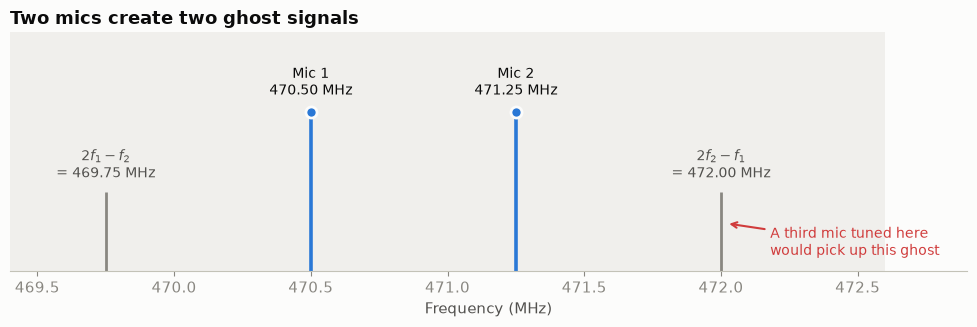

In [10]:
f1, f2 = 470.50, 471.25
print(f"2 x f1 - f2 = {2 * f1 - f2:.2f} MHz")
print(f"2 x f2 - f1 = {2 * f2 - f1:.2f} MHz")
plots.plot_ghost_example();

The count grows fast. $n$ carriers make $n(n-1)$ two-tone and $\binom{n}{2}(n-2)$ three-tone third-order products. Shure's page says three transmitters "may generate six in-band 3rd order" products [1]. Our formula gives nine for three carriers because it counts every two-tone and three-tone product wherever it lands, so the two counts measure different things.

In [11]:
for n in (3, 5, 10, 40):
    c = engine.count_third_order_products(n)
    print(f"{n:>2} mics: {c['two-tone']:>6,} two-tone + {c['three-tone']:>6,} three-tone = {c['total']:>6,}")

 3 mics:      6 two-tone +      3 three-tone =      9
 5 mics:     20 two-tone +     30 three-tone =     50
10 mics:     90 two-tone +    360 three-tone =    450
40 mics:  1,560 two-tone + 29,640 three-tone = 31,200


## 2. Using the tool

**The story.** The Humanities Theatre in Hagey Hall at the University of Waterloo seats up to 721 people [3]. Its technical specifications list three Shure ULD handheld microphones and three Shure ULD wireless body-pack transmitters [4]. Suppose a show uses five of those six Shure channels at once.

The venue pages give no frequency bands or receiver models. So the band below, 470 to 474 MHz, is illustrative, and so is the exclusion further down. A real plan needs the receivers' actual tuning range and a check of local TV channels.

**The rules.** Carriers at least 500 kHz apart (our demo choice, not a vendor rule) and no third-order product within 250 kHz of any carrier [1]. The tool lays a 250 kHz grid over the band. The top edge is left out, so that gives 16 frequencies, which means 16 qubits.

Mic plan: 5 mics, 16 allowed frequencies (16 qubits)
Rules: mics at least 500 kHz apart, no third-order product within 250 kHz of a mic
  Mic 1: 470.000 MHz
  Mic 2: 470.500 MHz
  Mic 3: 471.500 MHz
  Mic 4: 472.750 MHz
  Mic 5: 473.500 MHz
Check: No spacing problems and no third-order product within the guard of any mic.
How it was found: QAOA with 3 layers (CVaR (alpha=0.1) objective), 8,000 samples from Qiskit's StatevectorSampler.
  7.1% of samples were IM-free plans. A plan picked at random is IM-free 0.55% of the time (counted over all 4,368 plans).
  This plan was the most common clean sample (0.5% of samples).
Saved outputs/plan_humanities_theatre.csv


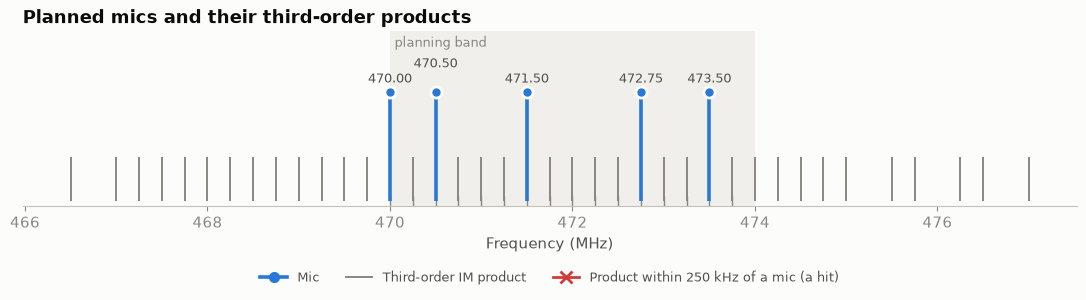

In [12]:
plan = plan_mics(band="470-474 MHz", mics=5, step="250 kHz", spacing="500 kHz",
                 im_guard="250 kHz", csv_path="outputs/plan_humanities_theatre.csv")

The plan is saved as a CSV file that a sound tech can open in a spreadsheet:

In [13]:
print(open(plan.csv_path).read())

mic,frequency_mhz
1,470.000
2,470.500
3,471.500
4,472.750
5,473.500



Now suppose 472.0 to 472.5 MHz is already in use by something else in the building (an illustrative exclusion). One extra argument handles it. Three grid points drop out, so this run uses 13 qubits.

Mic plan: 5 mics, 13 allowed frequencies (13 qubits)
Rules: mics at least 500 kHz apart, no third-order product within 250 kHz of a mic
Kept clear: 472.000 MHz to 472.500 MHz
  Mic 1: 470.000 MHz
  Mic 2: 470.500 MHz
  Mic 3: 471.250 MHz
  Mic 4: 472.750 MHz
  Mic 5: 473.750 MHz
Check: No spacing problems and no third-order product within the guard of any mic.
How it was found: QAOA with 3 layers (CVaR (alpha=0.1) objective), 8,000 samples from Qiskit's StatevectorSampler.
  10.8% of samples were IM-free plans. A plan picked at random is IM-free 0.62% of the time (counted over all 1,287 plans).
  This plan was the most common clean sample (2.2% of samples).
Saved outputs/plan_with_exclusion.csv


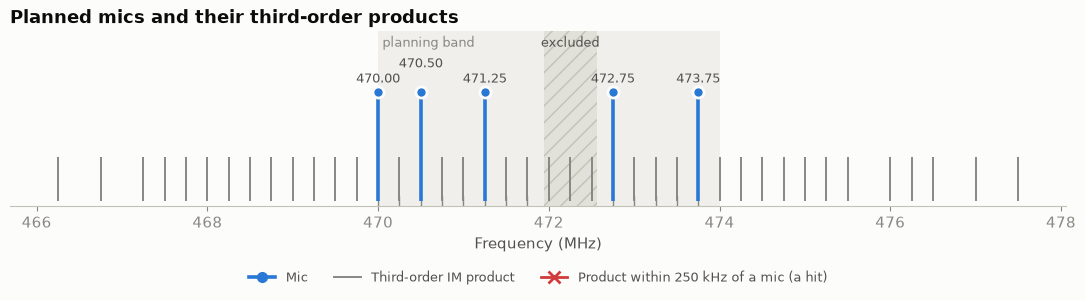

In [14]:
plan_x = plan_mics(band="470-474 MHz", mics=5, step="250 kHz", spacing="500 kHz", im_guard="250 kHz",
                   exclude=["472.0-472.5 MHz"], csv_path="outputs/plan_with_exclusion.csv")

## 3. How it works

**The rules become a cost function.** Each allowed frequency $k$ gets a bit $x_k$, which is 1 when a mic sits there. There are three kinds of conflict:

- $P$: pairs of frequencies closer than the carrier spacing.
- $T$: triples where a two-tone product $2f_k - f_l$ lands within the IM guard of a third mic $f_m$.
- $Q$: quadruples where a three-tone product $f_k + f_l - f_p$ lands within the IM guard of a fourth mic $f_m$.

Each conflicting set counts once:

$$C(x) = \sum_{(k,l)\in P} x_k x_l \;+\; w_3 \sum_{(k,l,m)\in T} x_k x_l x_m \;+\; w_3 \sum_{(k,l,p,m)\in Q} x_k x_l x_p x_m, \qquad \sum_k x_k = n, \qquad w_3 = 1 .$$

A plan is IM-free exactly when $C(x) = 0$, and any $w_3 > 0$ gives the same clean plans.

**The cost becomes qubits.** Substituting $x_k = (1 - Z_k)/2$ turns $C$ into a sum of Pauli-Z strings with up to four $Z$'s,

$$H_C = \sum_{S} c_S \prod_{k \in S} Z_k ,$$

which is diagonal, with $C(x)$ on the diagonal. Qiskit holds it as a `SparsePauliOp`.

**The circuit keeps the mic count.** QAOA prepares

$$|\psi(\boldsymbol\gamma, \boldsymbol\beta)\rangle = U_M(\beta_p)\, e^{-i\gamma_p H_C} \cdots U_M(\beta_1)\, e^{-i\gamma_1 H_C}\, |D^N_n\rangle .$$

- The start is the Dicke state $|D^N_n\rangle = \binom{N}{n}^{-1/2} \sum_{|x| = n} |x\rangle$: every $n$-mic plan with equal weight. We build it with the deterministic circuit of Bärtschi and Eidenbenz [8].
- The mixer is $U_M(\beta) = e^{-i\beta H_{\mathrm{odd}}}\, e^{-i\beta H_{\mathrm{even}}}$, where $H_{\mathrm{even}} = \tfrac12 \sum_{k\ \mathrm{even}} (X_k X_{k+1} + Y_k Y_{k+1})$ and $H_{\mathrm{odd}}$ is the same sum over the odd pairs plus the pair that closes the ring [9, 10]. Each $XX + YY$ term only swaps $|01\rangle$ and $|10\rangle$. It moves a mic to a neighbouring frequency and never adds or removes one.
- This product is not exactly $e^{-i\beta H_{XY}}$, because neighbouring pairs do not commute. It is what the circuit does, and our fast simulation uses the same product.
- So every sample has exactly $n$ mics, with no penalty weight to tune. The circuit is built with Qiskit's `qaoa_ansatz` function. The `QAOAAnsatz` class is deprecated in Qiskit 2.x.

**An honest note.** On this grid the guard means "lands exactly on a mic", and the spacing rule forbids neighbouring points. So an IM-free plan is a set whose pairwise differences are all distinct and never 1: a Golomb ruler (a Sidon set) with no gap of 1. The link between IM-free channels and these rulers goes back to Babcock in 1953 [14]. The engine handles any guard, step and exclusion, but this demo instance is that classic puzzle.

In [15]:
inst = plan.instance
print(inst.describe())
H_C = cost.cost_operator(inst)
zs = cost.z_strings_by_weight(H_C)
print("Z-strings by weight:", zs, "| total:", sum(zs.values()))

16 allowed frequencies, 5 mics
band 470.000 MHz to 474.000 MHz (top edge excluded), step 250 kHz
carrier spacing at least 500 kHz, IM products must stay at least 250 kHz from every carrier
conflicting sets: 15 pairs, 56 triples, 252 quadruples
Z-strings by weight: {1: 16, 2: 120, 3: 560, 4: 252} | total: 948


The pieces at a size small enough to print: the Dicke circuit for two mics on four frequencies, and the XY mixer's terms in the order Qiskit synthesizes them.

In [16]:
print(quantum.dicke_circuit(4, 2).draw("text"))
print(quantum.xy_mixer_operator(4))

                                                                             »
q_0: ────────────────────────────────────────────────────────────────────────»
                                     ┌─────────┐          ┌────────────┐     »
q_1: ─────────────────────────────■──┤ Ry(π/2) ├──■────■──┤ Ry(1.9106) ├──■──»
     ┌───┐     ┌──────────┐       │  └────┬────┘  │  ┌─┴─┐└─────┬──────┘┌─┴─┐»
q_2: ┤ X ├──■──┤ Ry(2π/3) ├──■────┼───────■───────┼──┤ X ├──────■───────┤ X ├»
     ├───┤┌─┴─┐└────┬─────┘┌─┴─┐┌─┴─┐     │     ┌─┴─┐└───┘              └───┘»
q_3: ┤ X ├┤ X ├─────■──────┤ X ├┤ X ├─────■─────┤ X ├────────────────────────»
     └───┘└───┘            └───┘└───┘           └───┘                        »
«          ┌───────────┐          ┌─────────┐     
«q_0: ──■──┤ Ry(1.231) ├──■────■──┤ Ry(π/2) ├──■──
«       │  └─────┬─────┘  │  ┌─┴─┐└────┬────┘┌─┴─┐
«q_1: ──┼────────■────────┼──┤ X ├─────■─────┤ X ├
«     ┌─┴─┐      │      ┌─┴─┐└───┘           └───┘
«q_2: ┤ X ├──────■──────┤ X ├─────

## 4. Checks

**The cost operator matches the classical cost.** At 12 qubits every basis state is checked with Qiskit's own matrix. At 16 qubits, 32 random basis states are checked with `Statevector` expectation values, and all 65,536 by a direct parity sum.

In [17]:
small = engine.build_instance("470-473 MHz", mics=4)
print(f"{small.n_points} qubits:", cost.check_diagonal(small, cost.cost_operator(small)))
print("16 qubits:", cost.check_diagonal(inst, H_C, n_spot=32))

12 qubits: {'method': 'all 4096 basis states, Qiskit to_matrix', 'max_error': 0.0, 'states': 4096}


16 qubits: {'method': '32 random states via Statevector, plus all 65536 by direct parity', 'max_error': 0.0, 'spot_error': 0.0, 'full_error': 0.0, 'states': 65536}


**The mixer never changes the mic count**, and Qiskit's synthesis of the mixer is exactly the even-then-odd product (checked on 6 qubits against explicit `RXX` and `RYY` gates).

In [18]:
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import Operator, SparsePauliOp, Statevector

n = 6
qc = QuantumCircuit(n)
qc.append(PauliEvolutionGate(quantum.xy_mixer_operator(n), time=0.41), range(n))
U = Operator(transpile(qc, basis_gates=quantum.BASIS, optimization_level=1)).data
weight = np.array([bin(i).count("1") for i in range(2 ** n)])
print("largest amplitude that changes the mic count:", np.abs(U[weight[:, None] != weight[None, :]]).max())
V = Operator(quantum.xy_mixer_circuit(n, 0.41)).data
print("synthesized mixer equals the even-then-odd product:", np.allclose(U, U[0, 0] / V[0, 0] * V))

largest amplitude that changes the mic count: 3.7030556577017753e-16
synthesized mixer equals the even-then-odd product: True


**The Dicke circuit makes the right state.**

In [19]:
dk = transpile(quantum.dicke_circuit(16, 5), basis_gates=quantum.BASIS, optimization_level=1)
fid = abs(np.vdot(quantum.dicke_vector(16, 5), Statevector(dk).data)) ** 2
print(f"Dicke(16, 5): fidelity {fid:.12f} with the exact state, {dk.count_ops()['cx']} CNOTs")

Dicke(16, 5): fidelity 1.000000000000 with the exact state, 560 CNOTs


**Through the Estimator primitive.** On an 8-frequency, 3-mic instance, `StatevectorEstimator` gives the circuit's $\langle C \rangle$, which must match the fast simulation, and the mic-count operator $N = \sum_k (1 - Z_k)/2$, which must have no spread at all.

In [20]:
from qiskit.primitives import StatevectorEstimator

s8 = engine.build_instance("470-472 MHz", mics=3)
fast8 = quantum.FastQAOA(s8)
g, b = [0.6, 0.9], [0.4, 0.3]
circ8 = quantum.compile_ansatz(quantum.build_ansatz(cost.cost_operator(s8), 3, reps=2))
bound8 = circ8.assign_parameters(quantum.angle_binding(circ8, g, b))
N_op = SparsePauliOp.from_sparse_list([("", [], s8.n_points / 2)] + [("Z", [k], -0.5) for k in range(s8.n_points)],
                                      s8.n_points)
evs = StatevectorEstimator().run([(bound8, [cost.cost_operator(s8), N_op, (N_op @ N_op).simplify()])]).result()[0].data.evs
print(f"<C>: circuit {evs[0]:.10f}, fast path {fast8.expectation(fast8.probs(g, b)):.10f}")
print(f"<N> = {evs[1]:.6f}, variance of N = {abs(evs[2] - evs[1] ** 2):.1e} (zero up to rounding)")

<C>: circuit 1.4623573132, fast path 1.4623573132
<N> = 3.000000, variance of N = 1.2e-13 (zero up to rounding)


## 5. Running QAOA

**Disclosure: angles are tuned on an exact NumPy simulation, then confirmed on the real circuit.** The cost layer is a diagonal phase, and the mixer acts pair by pair on the 4,368 five-mic plans, in the same order as the circuit. One evaluation takes well under a millisecond, against about 15 seconds for one statevector run of the full circuit. Nothing is approximated.

Two objectives are tried: the plain expectation $\langle C\rangle$, and CVaR with $\alpha = 0.1$, the mean cost of the best 10% of outcomes [11]. COBYLA tunes the angles layer by layer: a grid scan for $p = 1$, then the previous optimum stretched to $p + 1$ layers by interpolation, following Zhou et al. [12], plus six seeded random starts.

In [21]:
fast = quantum.FastQAOA(inst)
mean_res = quantum.tune(fast, max_p=3, kind="mean")
cvar_res = quantum.tune(fast, max_p=5, kind="cvar", alpha=0.1)
for name, rs in (("mean", mean_res), ("CVaR", cvar_res)):
    for r in rs:
        print(f"{name:>4}, p = {r.p}: IM-free probability {r.clean_prob:6.2%}, <C> = {r.expected_cost:.3f}")
print(f"uniform random: {fast.clean.mean():.2%}")

mean, p = 1: IM-free probability  1.75%, <C> = 2.293
mean, p = 2: IM-free probability  3.35%, <C> = 1.977
mean, p = 3: IM-free probability  3.87%, <C> = 1.723
CVaR, p = 1: IM-free probability  1.85%, <C> = 2.349
CVaR, p = 2: IM-free probability  4.03%, <C> = 2.095
CVaR, p = 3: IM-free probability  6.96%, <C> = 1.976
CVaR, p = 4: IM-free probability 10.00%, <C> = 1.795
CVaR, p = 5: IM-free probability 12.12%, <C> = 1.744
uniform random: 0.55%


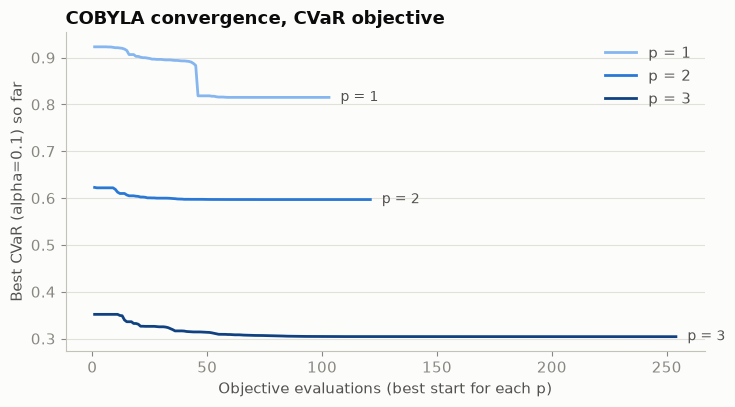

In [22]:
plots.plot_convergence(cvar_res[:3], "COBYLA convergence, CVaR objective");

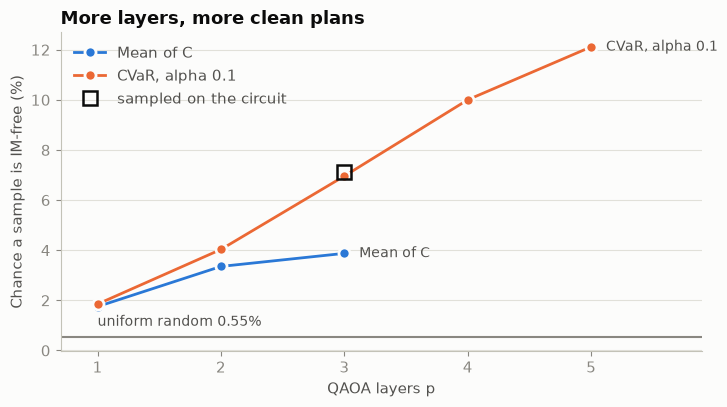

In [23]:
plots.plot_clean_vs_p({"Mean of C": mean_res, "CVaR, alpha 0.1": cvar_res}, fast.clean.mean(),
                      sampled=(3, plan.clean_share));

CVaR gives more IM-free samples, so `plan_mics` uses it with $p = 3$. Layers 4 and 5 ran only on the fast simulation, to keep this notebook quick. The mean objective stalls near 4%. The $p = 3$ CVaR angles here are the same ones `plan_mics` used in section 2, because both runs use the same seed:

In [24]:
best = cvar_res[2]
print("same angles as plan_mics:", np.allclose(best.gammas, plan.tuning[-1].gammas)
      and np.allclose(best.betas, plan.tuning[-1].betas))
print("gamma =", np.round(best.gammas, 4), " beta =", np.round(best.betas, 4))

same angles as plan_mics: True
gamma = [-0.6976 -1.0003 -1.1599]  beta = [0.3039 0.2512 0.1991]


**The real circuit at those angles.** `qaoa_ansatz` with the Dicke start and XY mixer, transpiled to `cx, rz, sx, x`, run as a Qiskit `Statevector` and compared with the fast simulation.

In [25]:
circ = quantum.compile_ansatz(quantum.build_ansatz(H_C, 5, reps=3))
agree = quantum.compare_with_circuit(fast, circ, best.gammas, best.betas)
print(f"fidelity {agree['fidelity']:.12f}")
print(f"probability outside the 5-mic plans {agree['leakage']:.1e}")
print(f"largest probability difference {agree['max_prob_diff']:.1e}  ({agree['seconds']:.0f} s for the statevector run)")

fidelity 1.000000000000
probability outside the 5-mic plans -6.9e-14
largest probability difference 3.0e-16  (16 s for the statevector run)


**The samples.** `plan_mics` drew 8,000 shots from `StatevectorSampler`. The most common ones:

In [26]:
top = sorted(plan.counts.items(), key=lambda kv: -kv[1])[:8]
for m, c in top:
    idx = engine.mask_to_indices(m)
    print(f"{c:4d} shots  {', '.join(f'{inst.freqs[i] / 1e6:.2f}' for i in idx)} MHz  "
          f"conflicting sets: {engine.cost_of(inst, idx):.0f}")
print(f"\nIM-free samples: {plan.clean_share:.2%} (exact {best.clean_prob:.2%}), uniform random {plan.random_share:.2%}")

  40 shots  470.00, 470.50, 471.50, 472.75, 473.50 MHz  conflicting sets: 0
  37 shots  470.00, 471.50, 472.00, 472.75, 473.75 MHz  conflicting sets: 0
  34 shots  470.00, 471.00, 472.50, 473.25, 473.75 MHz  conflicting sets: 0
  33 shots  470.25, 471.00, 472.00, 472.50, 473.25 MHz  conflicting sets: 1
  32 shots  470.50, 471.25, 471.75, 472.75, 473.50 MHz  conflicting sets: 1
  29 shots  470.00, 470.50, 471.50, 472.25, 473.50 MHz  conflicting sets: 0
  29 shots  470.00, 471.50, 472.50, 473.25, 473.75 MHz  conflicting sets: 0
  29 shots  470.00, 470.75, 471.25, 472.75, 473.75 MHz  conflicting sets: 0

IM-free samples: 7.11% (exact 6.96%), uniform random 0.55%


## 6. Results against classical baselines

Every classical method below solves this instance at once. That is expected with 16 frequencies.

In [27]:
rows = [baselines.run_brute_force(inst), baselines.greedy(inst), baselines.simulated_annealing(inst)["result"],
        baselines.uniform_random(inst)["result"], baselines.milp_solve(inst)]
clean_starts, _ = baselines.greedy_all_starts(inst)
fmt = lambda idx: ", ".join(f"{inst.freqs[i] / 1e6:.2f}" for i in idx)
table = ["| Method | Plan (MHz) | IM-free | Time | Note |", "|---|---|---|---|---|"]
for r in rows:
    table.append(f"| {r.name} | {fmt(r.plan)} | {'yes' if r.clean else 'no'} | {r.seconds * 1e3:.1f} ms | {r.note} |")
table.append(f"| QAOA, p = 3, CVaR (this work) | {fmt(plan.plan_indices)} | {'yes' if plan.clean else 'no'} | "
             f"{plan.seconds['total']:.0f} s | {plan.clean_share:.1%} of 8,000 samples IM-free |")
display(Markdown("\n".join(table)))
print(f"Greedy from each of the {inst.n_points} starting points ends clean {clean_starts} times.")

| Method | Plan (MHz) | IM-free | Time | Note |
|---|---|---|---|---|
| Brute force (exact) | 470.00, 470.50, 471.25, 472.25, 473.75 | yes | 7.7 ms | 24 of 4368 plans are IM-free |
| Greedy | 470.00, 470.50, 471.25, 472.25, 473.75 | yes | 2.4 ms |  |
| Simulated annealing | 470.00, 470.50, 471.50, 472.75, 473.50 | yes | 75.9 ms | 50 of 50 runs ended clean |
| Uniform random | 470.00, 470.50, 471.50, 472.25, 473.50 | yes | 56.0 ms | 0.50% of 8000 random plans are IM-free |
| Integer program (SciPy milp) | 470.00, 470.50, 471.25, 472.25, 473.75 | yes | 81.7 ms | Optimization terminated successfully. (HiGHS Status 7: Optimal) |
| QAOA, p = 3, CVaR (this work) | 470.00, 470.50, 471.50, 472.75, 473.50 | yes | 27 s | 7.1% of 8,000 samples IM-free |

Greedy from each of the 16 starting points ends clean 8 times.


**QAOA against random.** The histogram compares the QAOA samples with the exact spread over all 4,368 plans, which is what the Dicke start alone would give.

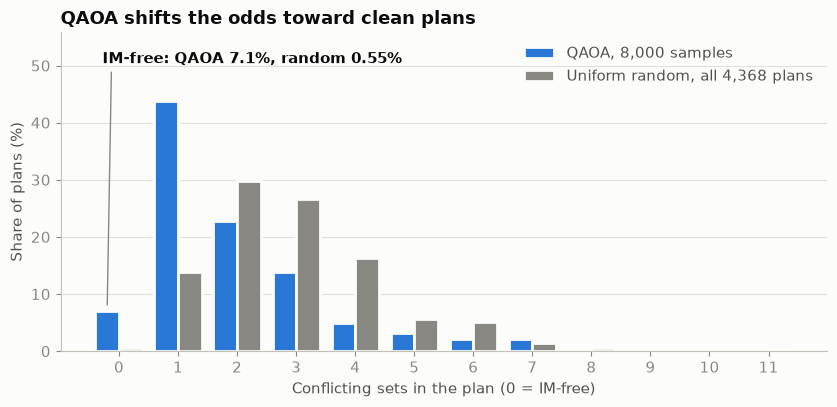

In [28]:
q_costs = [engine.cost_of(inst, engine.mask_to_indices(m)) for m in plan.counts]
q_w = np.array(list(plan.counts.values())) / plan.shots
plots.plot_histogram(q_costs, q_w, fast.cost, np.full(fast.dim, 1 / fast.dim),
                     labels=("QAOA, 8,000 samples", "Uniform random, all 4,368 plans"));

**What a newcomer might do.** Greedy is not our bad example, because greedy solves this instance (see the table). A person without software might instead space the mics evenly. That is the worst case: evenly spaced carriers are full of arithmetic progressions, and every progression puts a product right on a mic. The checker lists each hit.

20 problems: 0 spacing, 8 two-tone hits, 12 three-tone hits
  two-tone: 2 x 470.750 MHz - 470.000 MHz = 471.500 MHz, right on the mic at 471.500 MHz
  two-tone: 2 x 470.750 MHz - 471.500 MHz = 470.000 MHz, right on the mic at 470.000 MHz
  two-tone: 2 x 471.500 MHz - 470.000 MHz = 473.000 MHz, right on the mic at 473.000 MHz
  two-tone: 2 x 471.500 MHz - 470.750 MHz = 472.250 MHz, right on the mic at 472.250 MHz
  two-tone: 2 x 471.500 MHz - 472.250 MHz = 470.750 MHz, right on the mic at 470.750 MHz
  two-tone: 2 x 471.500 MHz - 473.000 MHz = 470.000 MHz, right on the mic at 470.000 MHz
  two-tone: 2 x 472.250 MHz - 471.500 MHz = 473.000 MHz, right on the mic at 473.000 MHz
  two-tone: 2 x 472.250 MHz - 473.000 MHz = 471.500 MHz, right on the mic at 471.500 MHz
  three-tone: 470.000 MHz + 472.250 MHz - 470.750 MHz = 471.500 MHz, right on the mic at 471.500 MHz
  three-tone: 470.000 MHz + 472.250 MHz - 471.500 MHz = 470.750 MHz, right on the mic at 470.750 MHz
  three-tone: 470.000 MHz 

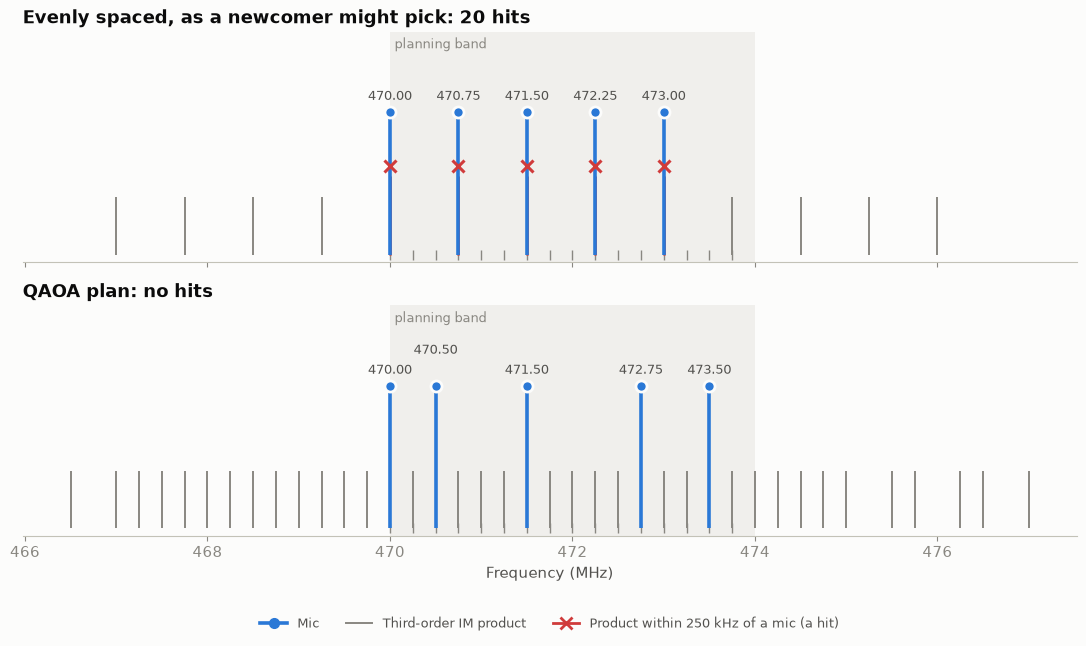

In [29]:
newcomer = (0, 3, 6, 9, 12)
nc = engine.check_indices(inst, newcomer)
print(nc.report())
hz = lambda idx: [inst.freqs[i] for i in idx]
plots.plot_side_by_side((hz(newcomer), f"Evenly spaced, as a newcomer might pick: {len(nc.violations)} hits"),
                        (hz(plan.plan_indices), "QAOA plan: no hits"), inst.spacing, inst.im_guard,
                        band=inst.band, grid=inst.freqs);

## 7. Resource card

Gate counts after transpiling to `cx, rz, sx, x` (optimization level 1, all-to-all connectivity), and the size of the same problem written as a QUBO.

In [30]:
card = quantum.resource_card(H_C, n_mics=5, reps=3)
qs = cost.qubo_size(inst)
zs = card["z_strings"]
rows = [("Qubits", f"{card['qubits']}"),
        ("Z-strings by weight 1 / 2 / 3 / 4", " / ".join(str(zs[w]) for w in (1, 2, 3, 4)) + f" ({sum(zs.values())} in all)"),
        ("Dicke start", f"{card['dicke']['cx']:,} CNOTs"),
        ("One cost layer, as built by qaoa_ansatz", f"{card['cost_layer']['cx']:,} CNOTs "
         f"(naive ladder count {card['cost_layer_naive_cx']:,}; {card['cost_layer_single_gate']['cx']:,} "
         "if synthesized as one PauliEvolutionGate)"),
        ("One XY mixer layer", f"{card['mixer_layer']['cx']} CNOTs"),
        ("Full circuit, p = 3", f"{card['full']['cx']:,} CNOTs, depth {card['full']['depth']:,}"),
        ("Transpile time, full circuit", f"{card['full']['transpile_s']:.2f} s"),
        ("Statevector run, full circuit", f"{agree['seconds']:.0f} s"),
        ("Same problem as a QUBO", f"{qs['variables']} binary variables (greedy Rosenberg; "
         f"{qs['best_variables']} to {qs['worst_variables']} over {qs['trials']} tie-break orders)")]
display(Markdown("| Item | Value |\n|---|---|\n" + "\n".join(f"| {a} | {b} |" for a, b in rows)))
print(f"{qs['qubits']} qubits here vs {qs['variables']} variables as a QUBO")

| Item | Value |
|---|---|
| Qubits | 16 |
| Z-strings by weight 1 / 2 / 3 / 4 | 16 / 120 / 560 / 252 (948 in all) |
| Dicke start | 560 CNOTs |
| One cost layer, as built by qaoa_ansatz | 4,006 CNOTs (naive ladder count 3,992; 2,570 if synthesized as one PauliEvolutionGate) |
| One XY mixer layer | 46 CNOTs |
| Full circuit, p = 3 | 12,716 CNOTs, depth 12,076 |
| Transpile time, full circuit | 0.09 s |
| Statevector run, full circuit | 16 s |
| Same problem as a QUBO | 121 binary variables (greedy Rosenberg; 114 to 125 over 200 tie-break orders) |

16 qubits here vs 121 variables as a QUBO


**Why the QUBO is bigger.** A QUBO allows only pairs of variables. Each triple or quadruple term needs auxiliary variables $y = x_i x_j$, held in place by Rosenberg penalty terms [13]. We count them greedily: replace the pair that appears in the most high-degree terms, and repeat until every term has two variables or fewer. A QUBO would also need a penalty to hold the mic count at 5.

**The other side of the trade.** The gate model pays in depth instead: about 4,000 CNOTs per cost layer and 12,716 for the whole $p = 3$ circuit. We have not run it on hardware, and we expect a circuit this deep to be dominated by noise on current devices.

## 8. Where it falls short

- **No speed-up.** QAOA is a heuristic with no proven advantage here, and we claim none.
- **Classically trivial at this size.** Brute force takes about 10 ms. Greedy solves it, and simulated annealing ends clean in 50 of 50 runs.
- **A modest gain over random.** At $p = 3$, 7.1% of samples are IM-free against 0.55% for random plans, about 13 times better. On the fast simulation, $p = 5$ reaches 12%. The angles were tuned by exact classical simulation, which is impossible at large sizes.
- **It is a Golomb-ruler search here.** With exact landings on a uniform grid, IM-free plans are Golomb rulers with no gap of 1, a connection known since 1953 [14].
- **A guard model simpler than a coordinator's.** Third-order products only (Shure also lists fifth-order ones [1]). No TV channel data, transmitter power, distance or receiver selectivity. A uniform grid, and every carrier treated alike.
- **Venue facts.** The band and the exclusion are illustrative, not the theatre's real setup.
- **Free vendor tools exist.** Shure's Wireless Workbench is free [15] and far more complete. Our contribution is a quantum route that models IM, behind a plain-English interface, not a replacement for those tools.

**Beyond the toy size.** Six IM-free mics with these rules need 21 grid points, and only two plans work:

In [31]:
six = engine.build_instance("470-475.25 MHz", mics=6)
bf6 = engine.brute_force(six)
print(f"6 mics: {six.n_points} points ({six.n_points} qubits), {bf6.n_plans:,} plans, {bf6.n_clean} IM-free:",
      [[f"{six.freqs[i] / 1e6:.2f}" for i in p] for p in bf6.best_plans])

6 mics: 21 points (21 qubits), 54,264 plans, 2 IM-free: [['470.00', '470.50', '472.00', '473.25', '474.25', '475.00'], ['470.00', '470.75', '471.75', '473.00', '474.50', '475.00']]


For 40 mics on this kind of grid, the 780 pairwise differences must be distinct and at least 2, so the largest is at least 781. The grid then needs at least 782 points, which is 782 qubits and about 195 MHz at 250 kHz steps. The number of conflicting sets on such a grid:

In [32]:
N40 = 782
T40, Q40 = engine.uniform_grid_term_counts(N40)
print(f"{N40} qubits: {T40:,} triple terms and {Q40:,} quadruple terms")
print(f"for comparison, 16 points: {engine.uniform_grid_term_counts(16)}")

782 qubits: 152,490 triple terms and 39,621,985 quadruple terms
for comparison, 16 points: (56, 252)


That is tens of millions of four-body terms in every cost layer. A real system would also work off-grid, with finer tuning steps and several bands. A practical quantum route at that size would need a much sparser model, problem decomposition, or both. That is open work.

## 9. References

1. Shure, "All about wireless intermodulation distortion". https://www.shure.com/en-US/insights/all-about-wireless-intermodulation-distortion
2. SoundPro, "RF coordination for live events" (2026 guide). https://soundpro.com/blogs/live-production/rf-coordination-live-events-guide-2026
3. University of Waterloo Theatres, "Our theatres". https://uwaterloo.ca/theatres/venue-rental/our-theatres
4. University of Waterloo Theatres, "Humanities Theatre technical specs". https://uwaterloo.ca/theatres/venue-rental/humanities-theatre/humanities-theatre-technical-specs
5. D-Wave, frequency-selection example. https://github.com/dwave-examples/frequency-selection
6. M. Vandelli, F. Ferrari, D. Dragoni, "Constraint-preserving quantum algorithm for the multi-frequency antenna placement problem", arXiv:2511.15566 (2025).
7. E. Farhi, J. Goldstone, S. Gutmann, "A Quantum Approximate Optimization Algorithm", arXiv:1411.4028 (2014).
8. A. Bärtschi, S. Eidenbenz, "Deterministic Preparation of Dicke States", arXiv:1904.07358 (2019).
9. S. Hadfield et al., "From the Quantum Approximate Optimization Algorithm to a Quantum Alternating Operator Ansatz", Algorithms 12(2), 34 (2019), arXiv:1709.03489.
10. Z. Wang, N. C. Rubin, J. M. Dominy, E. G. Rieffel, "XY-mixers: analytical and numerical results for QAOA", Phys. Rev. A 101, 012320 (2020), arXiv:1904.09314.
11. P. Kl. Barkoutsos et al., "Improving Variational Quantum Optimization using CVaR", Quantum 4, 256 (2020), arXiv:1907.04769.
12. L. Zhou et al., "Quantum Approximate Optimization Algorithm: Performance, Mechanism, and Implementation on Near-Term Devices", Phys. Rev. X 10, 021067 (2020), arXiv:1812.01041.
13. I. G. Rosenberg, "Reduction of bivalent maximization to the quadratic case", Cahiers du Centre d'Études de Recherche Opérationnelle 17, 71 to 74 (1975).
14. W. C. Babcock, "Intermodulation Interference in Radio Systems", Bell System Technical Journal 32, 63 to 73 (1953), doi:10.1002/j.1538-7305.1953.tb01422.x.
15. Shure, "Wireless Workbench". https://shure.com/en-us/products/software/wwb
16. A. Javadi-Abhari et al., "Quantum computing with Qiskit", arXiv:2405.08810 (2024).

In [33]:
print(f"Notebook runtime: {time.perf_counter() - T0:.0f} s")

Notebook runtime: 96 s
